## **Apa itu Hyperparameter?**
Sebelum model belajar, kita harus menentukan beberapa pengaturan terlebih dahulu. Pengaturan inilah yang disebut hyperparameter.

- **max_depth**: Menentukan kedalaman maksimum pohon.
- **min_samples_split**: Menentukan jumlah minimum data agar suatu node boleh dipecah.
- **min_samples_leaf**: Jumlah minimum data pada setiap daun (leaf).

**Grid Search** akan mencoba seluruh kombinasi. Pada GridSearchCV terdapat parameter cv=5 (umumnya) yang artinya menggunakan 5-Fold Cross Validation. Data training dibagi menjadi lima bagian. Skor akhir adalah rata-rata dari lima percobaan.

In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import(
    mean_absolute_error, 
    mean_squared_error,
    r2_score
)

In [45]:
df = pd.read_csv(r"E:\DigitalentDA\Datasets\dataset7.csv")

df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [46]:
df.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311.0,15.2,386.71,17.10,18.9


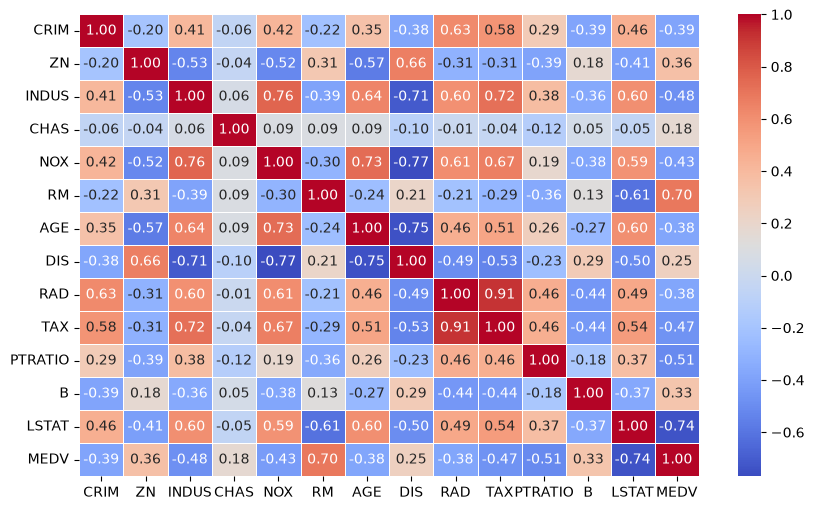

In [47]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

In [144]:
X = df.drop(columns=['MEDV'])

X1 = df[['RM', 'NOX', 'INDUS', 
        'TAX', 'RAD', 'CRIM', 
        'AGE', 'DIS', 'LSTAT',
        'PTRATIO']]

X2 = df[['RM', 'LSTAT', 'PTRATIO', 
         'NOX', 'TAX']]

y = df['MEDV']


In [145]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y, test_size=0.2, random_state=42
)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42
)

In [146]:
baseline_model = DecisionTreeRegressor(random_state=42)
baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_test)

baseline1_model = DecisionTreeRegressor(random_state=42)
baseline1_model.fit(X1_train, y1_train)
y1_pred = baseline1_model.predict(X1_test)

baseline2_model = DecisionTreeRegressor(random_state=42)
baseline2_model.fit(X2_train, y2_train)
y2_pred = baseline2_model.predict(X2_test)

In [153]:
hasil = pd.DataFrame({
    'Model': ['All Features', '10 Features', '5 Features'],
    'MSE': [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y1_test, y1_pred),
        mean_squared_error(y2_test, y2_pred),
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y1_test, y1_pred),
        mean_absolute_error(y2_test, y2_pred)
    ],
    'R2': [
        r2_score(y_test, y_pred),
        r2_score(y1_test, y1_pred),
        r2_score(y2_test, y2_pred)
    ]
})

print(hasil)

          Model        MSE       MAE        R2
0  All Features  17.815588  2.724510  0.757062
1   10 Features   8.759216  2.184314  0.880557
2    5 Features   8.295196  2.306863  0.886884


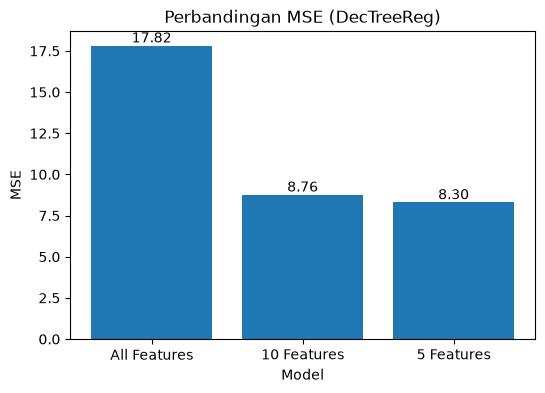

In [155]:
# Grafik MSE
plt.figure(figsize=(6,4))

plt.bar(hasil['Model'], hasil['MSE'])

plt.title('Perbandingan MSE (DecTreeReg)')
plt.xlabel('Model')
plt.ylabel('MSE')

# Menampilkan nilai di atas bar
for i, value in enumerate(hasil['MSE']):
    plt.text(i, value + 0.2, f'{value:.2f}', ha='center')

plt.show()

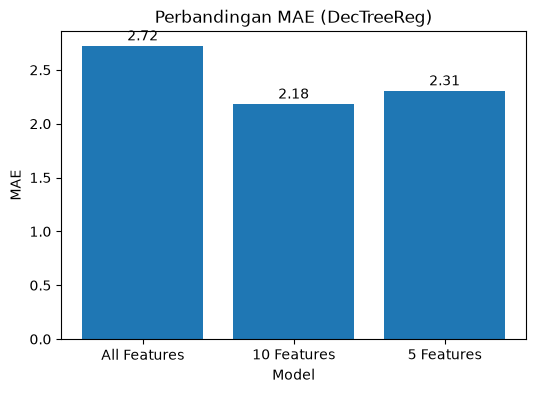

In [156]:
# Grafik MAE
plt.figure(figsize=(6,4))

plt.bar(hasil['Model'], hasil['MAE'])

plt.title('Perbandingan MAE (DecTreeReg)')
plt.xlabel('Model')
plt.ylabel('MAE')

for i, value in enumerate(hasil['MAE']):
    plt.text(i, value + 0.05, f'{value:.2f}', ha='center')

plt.show()

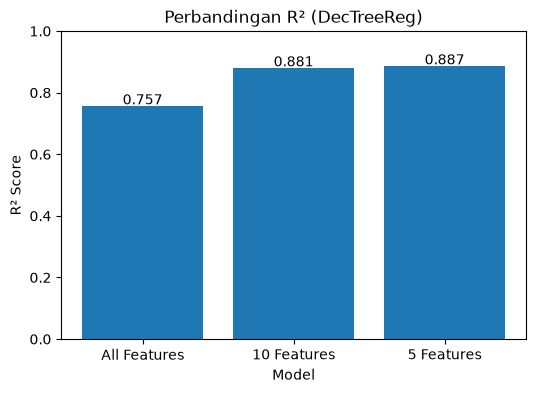

In [157]:
# Grafik R2
plt.figure(figsize=(6,4))

plt.bar(hasil['Model'], hasil['R2'])

plt.title('Perbandingan R² (DecTreeReg)')
plt.xlabel('Model')
plt.ylabel('R² Score')

for i, value in enumerate(hasil['R2']):
    plt.text(i, value + 0.005, f'{value:.3f}', ha='center')

plt.ylim(0,1)

plt.show()

In [166]:
param_grid = {
    'max_depth': [2, 3, 5, 7, 10],
    'min_samples_split': [2, 3, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4]
}

In [167]:
grid_search = GridSearchCV(
    estimator=baseline_model,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1
)

grid_search1 = GridSearchCV(
    estimator=baseline1_model,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1
)

grid_search2 = GridSearchCV(
    estimator=baseline2_model,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1
)

In [168]:
grid_search.fit(X_train, y_train)
grid_search1.fit(X1_train, y1_train)
grid_search2.fit(X2_train, y2_train)

c:\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Contr

In [170]:
print(grid_search.best_params_)
print(grid_search1.best_params_)
print(grid_search2.best_params_)

{'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 2}
{'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 2}
{'max_depth': 7, 'min_samples_leaf': 4, 'min_samples_split': 2}


In [171]:
print(grid_search.best_score_)
print(grid_search1.best_score_)
print(grid_search2.best_score_)

0.7266846948149782
0.7114170660214858
0.71873563193001


In [172]:
final_model = grid_search.best_estimator_
final1_model = grid_search1.best_estimator_
final2_model = grid_search2.best_estimator_

In [173]:
y_pred_final = final_model.predict(X_test)
y1_pred_final = final1_model.predict(X1_test)
y2_pred_final = final2_model.predict(X2_test)

In [174]:
hasil = pd.DataFrame({
    'Model Final': ['All Features', '10 Features', '5 Features'],
    'MSE': [
        mean_squared_error(y_test, y_pred_final),
        mean_squared_error(y1_test, y1_pred_final),
        mean_squared_error(y2_test, y2_pred_final),
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_final),
        mean_absolute_error(y1_test, y1_pred_final),
        mean_absolute_error(y2_test, y2_pred_final)
    ],
    'R2': [
        r2_score(y_test, y_pred_final),
        r2_score(y1_test, y1_pred_final),
        r2_score(y2_test, y2_pred_final)
    ]
})

print(hasil)

    Model Final        MSE       MAE        R2
0  All Features   9.907988  2.263664  0.864892
1   10 Features  18.703652  2.519350  0.744952
2    5 Features  15.432067  2.766676  0.789564


In [175]:
hasil_final = pd.DataFrame({
    'Feature': ['All Features', '10 Features', '5 Features'],
    'DecisionTree': [
        r2_score(y_test, y_pred),
        r2_score(y1_test, y1_pred),
        r2_score(y2_test, y2_pred)
    ],
    'GridSearch': [
        r2_score(y_test, y_pred_final),
        r2_score(y1_test, y1_pred_final),
        r2_score(y2_test, y2_pred_final)
    ]
})

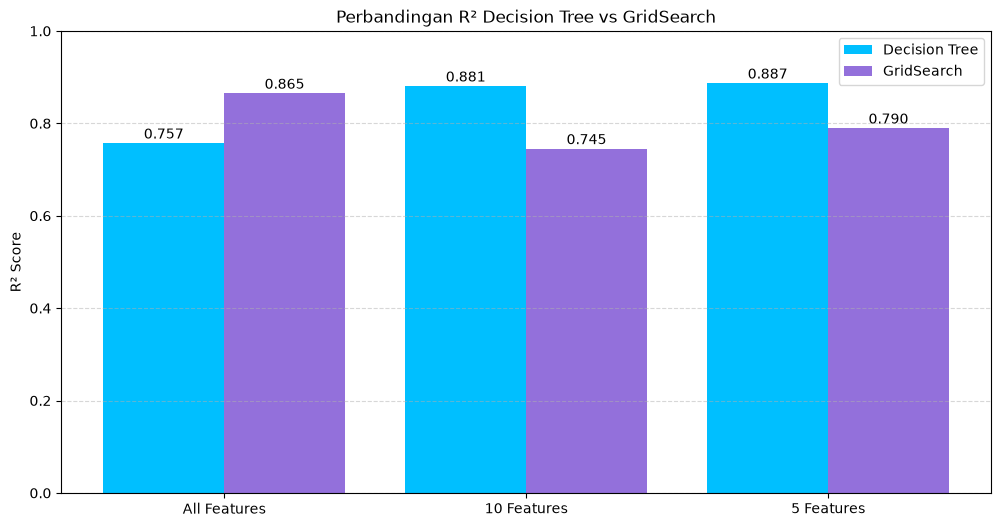

In [192]:
x = np.arange(len(hasil_final['Feature']))
width = 0.4

plt.figure(figsize=(12,6))

plt.bar(x - width/2, hasil_final['DecisionTree'], width, label='Decision Tree', color='deepskyblue')
plt.bar(x + width/2, hasil_final['GridSearch'], width, label='GridSearch', color='mediumpurple')

plt.xticks(x, hasil_final['Feature'])
plt.ylabel("R² Score")
plt.title("Perbandingan R² Decision Tree vs GridSearch")

plt.ylim(0,1)

# Nilai di atas batang
for i, v in enumerate(hasil_final['DecisionTree']):
    plt.text(x[i]-width/2, v+0.01, f"{v:.3f}", ha='center')

for i, v in enumerate(hasil_final['GridSearch']):
    plt.text(x[i]+width/2, v+0.01, f"{v:.3f}", ha='center')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()